# 01 · TorNet Veri Setini Tanıma

**Amaç:** Model eğitmeden önce veriyi anlamak.

1. `catalog.csv` dosyasını okuyup (203.133 örneğin tamamı, 38 MB) her yıldaki örnek ve tornado sayısını çıkarmak. **Radar verisini indirmeden.**
2. Veri setinin hazır eğitim/test ayrımında aynı fırtınanın iki tarafta da olup olmadığını kontrol etmek.
3. Gerçek radar görüntülerine bakmak: bir tornado, tornado çıkmamış bir uyarı ve rastgele bir fırtına.
4. Ön işlemenin önemli bilgiyi koruduğunu kontrol etmek.

Colab'da (CPU yeterli) ya da kendi bilgisayarında çalışır. Sadece birkaç yüz MB indirilir.

In [6]:
# --- Kurulum: hem Google Colab'da hem kendi bilgisayarında çalışır ---
import os, sys
from pathlib import Path

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive, userdata
    drive.mount("/content/drive")                     # işlenmiş veri Drive'da saklanır
    REPO = Path("/content/tornado-cnn")
    if not REPO.exists():
        try:                                          # repo private ise: Colab Secrets'taki token
            token = userdata.get("GITHUB_TOKEN") + "@"
        except Exception:                             # repo public ise token gerekmez
            token = ""
        !git clone -q https://{token}github.com/baevv/tornado-cnn.git {REPO}
    else:
        !git -C {REPO} pull -q
    %pip install -q h5netcdf h5py
    os.chdir(REPO)
else:
    REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

sys.path.insert(0, str(REPO))
print("Colab" if IN_COLAB else "Yerel", "| repo:", REPO)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Colab | repo: /content/tornado-cnn


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import paths, tornet, viz

cfg = paths.load_config()
DATA = paths.data_dir()
print("veri klasörü:", DATA)
print("ayarlar:", cfg)

veri klasörü: /content/drive/MyDrive/tornado-cnn/data
ayarlar: {'years': [2015, 2017, 2019], 'variables': ['DBZ', 'VEL'], 'sweep': 0, 'frame': -1, 'drive_subdir': 'tornado-cnn'}


## 1. Katalog

Her satır bir örnek. `category` sütununun üç değeri var:

| category | anlamı | bizim etiketimiz |
|---|---|---|
| `TOR` | doğrulanmış tornado | **1** |
| `WRN` | tornado uyarısı verilmiş ama tornado çıkmamış | 0 |
| `NUL` | rastgele seçilmiş fırtına, tornado yok | 0 |

`WRN` örnekleri **zor negatifler**: meteorologların uyarı verecek kadar tehlikeli bulduğu ama tornado çıkmayan fırtınalar.

In [8]:
cat = tornet.get_catalog(DATA)
print(f"{len(cat):,} örnek")
cat.head(3)

203,133 örnek


,type,start_time,end_time,lat,lon,episode_id,event_id,site_name,ef_number,category,az_min,az_max,rng_min,rng_max,filename,year,label
0,train,2013-08-31 23:25:00,2013-08-31 23:40:00,41.628078,-77.844040,77417,467173,KBGM,-1.0,NUL,218.0,278.0,136680.0,196680.0,train/2013/NUL_130831_234007_KBGM_467173s_B5.nc,2013,0
1,train,2013-08-31 23:29:00,2013-08-31 23:44:00,42.125849,-75.318244,77417,467173,KBGM,-1.0,NUL,68.0,128.0,25560.0,85560.0,train/2013/NUL_130831_234422_KBGM_467173s_K7.nc,2013,0
2,train,2013-08-31 23:34:00,2013-08-31 23:49:00,42.006403,-77.190035,77417,467173,KBGM,-1.0,NUL,228.0,288.0,71860.0,131860.0,train/2013/NUL_130831_234837_KBGM_467173s_X3.nc,2013,0


Yıl yıl dağılım. `tornado_%` sınıf dengesizliğini, `TOR_per_GB` indirilen her GB başına kaç tornado örneği düştüğünü gösterir.

In [9]:
per_year = pd.crosstab(cat["year"], cat["category"])
per_year["total"] = per_year.sum(axis=1)
per_year["tornado_%"] = (100 * per_year["TOR"] / per_year["total"]).round(1)
sizes_gb = {2013: 3.2, 2014: 15.1, 2015: 17.4, 2016: 16.0, 2017: 15.1,
            2018: 12.5, 2019: 18.2, 2020: 17.0, 2021: 18.0, 2022: 19.0}   # Zenodo'daki arşiv boyutu
per_year["archive_GB"] = pd.Series(sizes_gb)
per_year["TOR_per_GB"] = (per_year["TOR"] / per_year["archive_GB"]).round(0)
per_year

category,NUL,TOR,WRN,total,tornado_%,archive_GB,TOR_per_GB
year,,,,,,,
2013,2801,389,881,4071,9.6,3.2,122.0
2014,11279,1529,7185,19993,7.6,15.1,101.0
2015,14742,1754,7127,23623,7.4,17.4,101.0
2016,12930,1501,7311,21742,6.9,16.0,94.0
2017,10851,1623,7598,20072,8.1,15.1,107.0
2018,11165,1195,5518,17878,6.7,12.5,96.0
2019,13425,2011,9183,24619,8.2,18.2,110.0
2020,14702,1263,6938,22903,5.5,17.0,74.0
2021,14546,1508,7265,23319,6.5,18.0,84.0


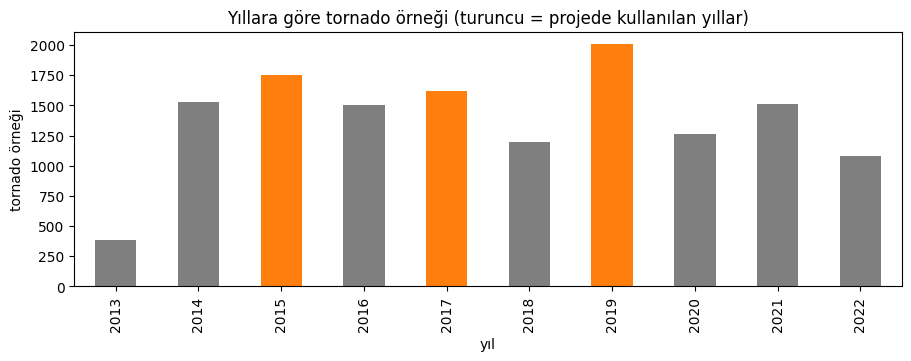

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.5), layout="constrained")
per_year["TOR"].plot.bar(ax=ax, color=["C1" if y in cfg["years"] else "C7" for y in per_year.index])
ax.set_xlabel("yıl")
ax.set_ylabel("tornado örneği")
ax.set_title("Yıllara göre tornado örneği (turuncu = projede kullanılan yıllar)")
plt.show()

### Projede kullanılan yıllar

2013 küçük, çünkü veri Ağustos 2013'ün sonunda başlıyor. İndirilen GB başına en çok tornado örneği 2019 ve 2017'de. 2015 ise veri miktarını artırıyor.

In [11]:
sel = cat[cat["year"].isin(cfg["years"])]
summary = pd.crosstab(sel["type"], sel["category"], margins=True)
print("Yıllar:", cfg["years"], f"| {len(sel):,} örnek | {sel['label'].sum():,} tornado (%{100*sel['label'].mean():.1f})")
summary

Yıllar: [2015, 2017, 2019] | 68,314 örnek | 5,388 tornado (%7.9)


category,NUL,TOR,WRN,All
type,,,,
test,5988,797,4293,11078
train,33030,4591,19615,57236
All,39018,5388,23908,68314


### Tornado şiddeti (EF ölçeği)

EF0 en zayıf, EF4 en güçlülerden. Modelimiz EF derecesini tahmin etmeyecek, ama sonra modelin güçlü tornadoları daha kolay bulup bulmadığına bakabiliriz.

In [12]:
tor = cat[cat["category"] == "TOR"]
pd.crosstab(tor["year"], tor["ef_number"].astype(int), margins=True)

ef_number,0,1,2,3,4,All
year,,,,,,
2013,73,128,144,25,19,389
2014,611,559,206,114,39,1529
2015,752,712,199,69,22,1754
2016,603,575,214,92,17,1501
2017,602,747,236,38,0,1623
2018,538,473,145,39,0,1195
2019,745,818,299,138,11,2011
2020,505,526,164,43,25,1263
2021,572,640,216,59,21,1508


## 2. Eğitim/test ayrımı kontrolü

Veri seti hazır bir `type` sütunuyla geliyor (`train` / `test`). Aynı fırtına olayı (`episode_id`) iki tarafta da varsa
model daha önce gördüğü bir fırtınayla test edilmiş olur. Buna **veri sızıntısı** denir ve başarıyı olduğundan yüksek gösterir.
Bu fırtınalar eğitim kümesinden çıkarılacak.

In [13]:
train_eps = set(cat.loc[cat["type"] == "train", "episode_id"])
test_eps = set(cat.loc[cat["type"] == "test", "episode_id"])
overlap = train_eps & test_eps
print(f"test fırtınası: {len(test_eps):,} | eğitimde de olan: {len(overlap)}")
print(f"bu fırtınalara ait eğitim örneği: {cat[(cat['type']=='train') & cat['episode_id'].isin(overlap)].shape[0]}")

test fırtınası: 1,780 | eğitimde de olan: 25
bu fırtınalara ait eğitim örneği: 296


## 3. Gerçek radar örneklerine bakış

2017 arşivinin sadece başını okuyup her kategoriden birkaç örnek bulunca duruyoruz (15 GB yerine birkaç yüz MB).

Bir örneğin içinde ne var (dosyalardan kontrol edildi):

* 6 radar değişkeni, her biri `(time=4, azimuth=120, range=240, sweep=2)` boyutunda
* 5 dakika arayla 4 zaman adımı; 2 tarama açısı (0,5° ve 0,9°)
* fırtınanın çevresinde 60° × 60 km'lik bir pencere
* ölçüm yapılamayan pikseller `NaN`

İki değişken kullanıyoruz:

* **DBZ (yansıtıcılık):** Havada ne kadar yağmur/dolu olduğunu gösterir. Tornadolu fırtınalarda sık sık **kanca** şekli görülür.
* **VEL (radyal hız):** Rüzgarın radara doğru (mavi) ya da radardan uzağa (kırmızı) esmesi. Tornado bir **hız çifti** olarak görünür:
  güçlü mavi ve güçlü kırmızının yan yana durması, yani dönme.

In [14]:
samples = tornet.sample_from_tar(tornet.tar_url(2017), per_category={"TOR": 2, "WRN": 1, "NUL": 1})
for name in samples:
    print(name)

train/2017/NUL_170605_221049_KRAX_1079025n_R6.nc
train/2017/WRN_170912_023550_KLTX_1079806n_E2.nc
train/2017/TOR_170706_021510_KLWX_713480_S2.nc
train/2017/TOR_170516_233707_KGLD_698091_B0.nc


Bir örnek dosyanın içeriği:

In [15]:
ds0 = next(iter(samples.values()))
ds0

<xarray.Dataset> Size: 6MB
Dimensions:            (sweep: 2, time: 4, lims: 2, azimuth: 120, range: 240)
Coordinates:
  * time               (time) datetime64[ns] 32B 2017-06-05T21:55:30 ... 2017...
  * azimuth            (azimuth) float32 480B 38.25 38.75 39.25 ... 97.25 97.75
  * range              (range) float32 960B 1.828e+04 1.853e+04 ... 7.803e+04
Dimensions without coordinates: sweep, lims
Data variables:
    elevation          (sweep) float64 16B 0.5 0.9
    frame_labels       (time) uint8 4B 0 0 0 0
    nyquist_velocity   (time, sweep) float32 32B 26.39 33.39 ... 33.39 33.39
    azimuth_limits     (lims) float32 8B 38.0 98.0
    range_limits       (lims) float32 8B 1.815e+04 7.815e+04
    DBZ                (time, azimuth, range, sweep) float32 922kB -6.5 ... nan
    VEL                (time, azimuth, range, sweep) float32 922kB 4.0 ... nan
    KDP                (time, azimuth, range, sweep) float32 922kB nan ... 0.0
    RHOHV              (time, azimuth, range, sweep) float32 922kB 1.052 ... nan
    ZDR                (time, azimuth, range, sweep) float32 922kB 3.75 ... -8.0
    WIDTH              (time, azimuth, range, sweep) float32 922kB 2.0 ... nan
    range_folded_mask  (time, azimuth, range, sweep) uint8 230kB 0 0 1 ... 0 0 0
Attributes:
    site_name:           KRAX
    site_lat:            35.665556
    site_lon:            -78.489722
    MissingDataFlag:     -999.0
    ef_number:           -1.0
    event_id:            1079025
    episode_id:          183409
    tornado_start_time:  
    tornado_end_time:    
    category:            NUL
    scit_id:             R6
    storm_event_url:     https://www.ncdc.noaa.gov/stormevents/eventdetails.j...

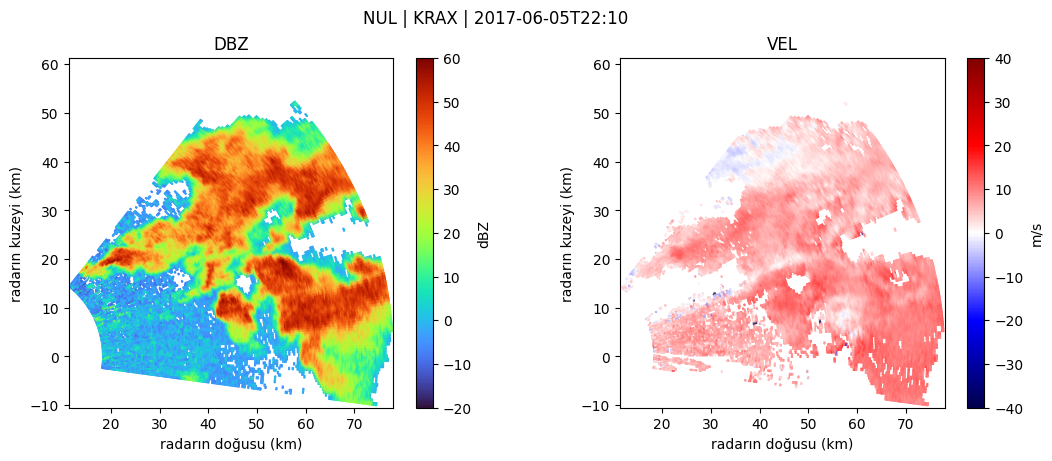

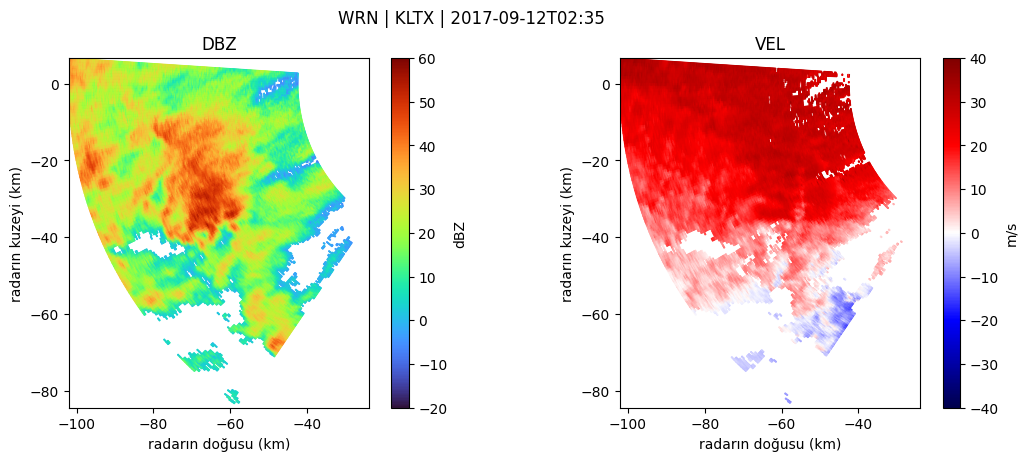

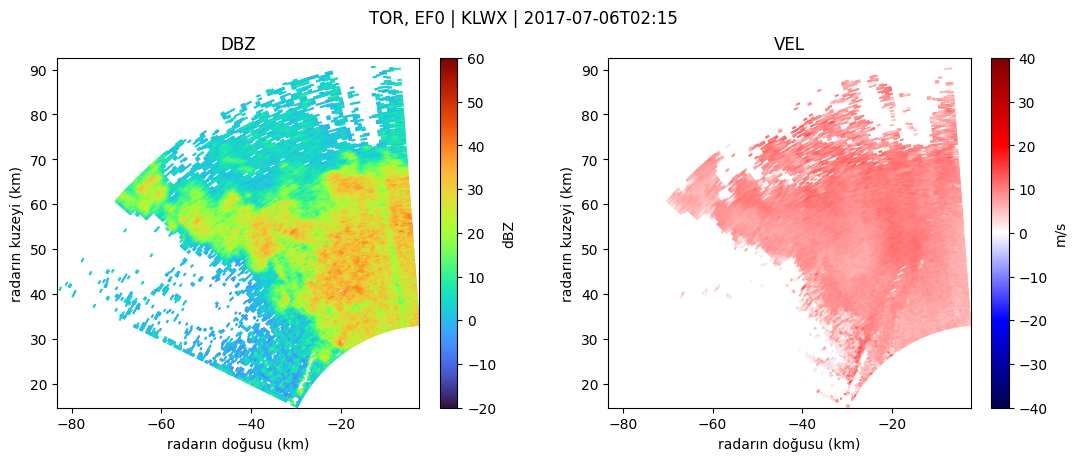

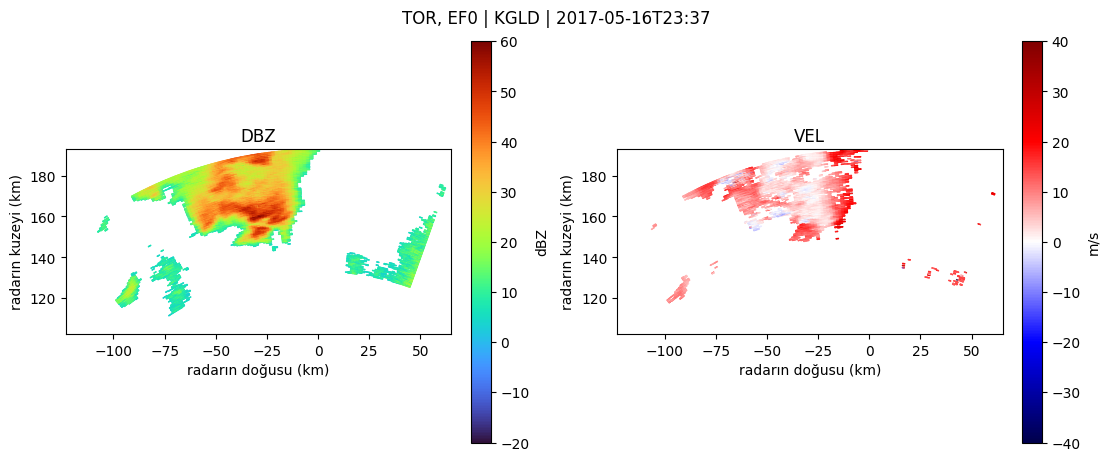

In [16]:
for name, ds in samples.items():
    viz.plot_sample(ds)
    plt.show()

Not: Zayıf tornadolar (EF0, EF1) radarda her zaman gözle belli olmaz. Görevi zorlaştıran şey de bu.

### Bir tornado örneğinin 4 zaman adımı

`frame_labels` tornadonun yerde olduğu kareleri işaretler. Örneğin etiketi **son** karenin etiketidir.
Önceki kareler ileride, RNN/LSTM haftalarında işe yarayabilir.

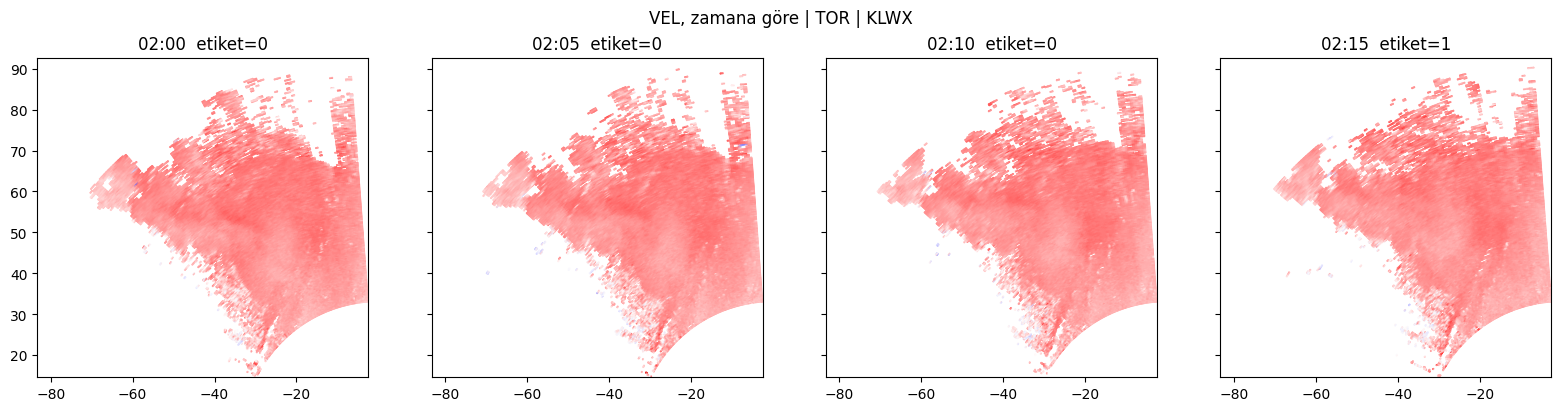

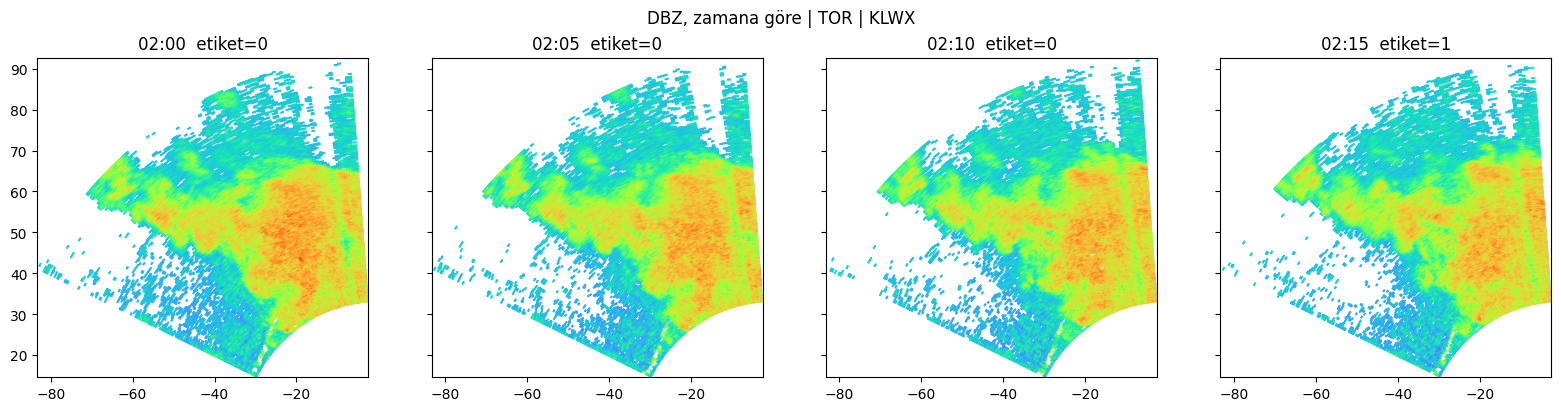

In [17]:
tor_name = next(n for n in samples if "/TOR_" in n)
viz.plot_frames(samples[tor_name], "VEL")
plt.show()
viz.plot_frames(samples[tor_name], "DBZ")
plt.show()

## 4. Ağın göreceği girdi

Ön işleme adımları (`src/tornet.py`):

1. **DBZ ve VEL**, **en alçak tarama (0,5°)** ve **son zaman adımı** alınır → boyut `(2, 120, 240)`.
2. Değerler **sabit fiziksel aralıklarla** ölçeklenir (DBZ −20…60 dBZ, VEL −60…60 m/s). Verinin kendi istatistikleri kullanılmaz, böylece test kümesinden bilgi sızmaz.
3. `uint8` olarak saklanır (piksel başına 1 bayt, 4 kat daha küçük). `0` değeri boş pikseller için ayrılmıştır.
4. Yüklenirken `[-1, 1]` aralığına çevrilir ve boş pikseller fiziksel olarak anlamlı bir değerle doldurulur: DBZ → en düşük değer (yankı yok), VEL → 0 (hareket yok).

Ağ kutupsal ızgarayı doğrudan görür (satırlar = açı, sütunlar = mesafe). Bu yüzden şekiller yukarıdaki haritaya göre gerilmiş görünür.

saklanan: (2, 120, 240) uint8 | ağın girdisi: (2, 120, 240) float32 [-1.00, 0.57]
kanal başına boş piksel (%): [18.4 31.8]


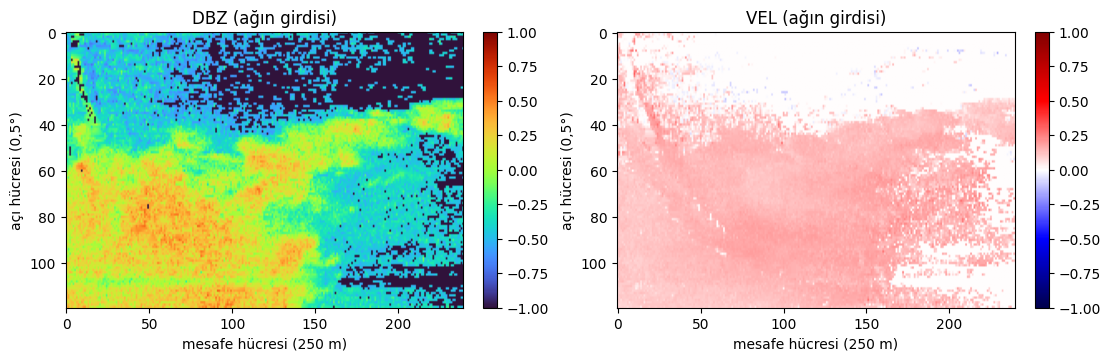

In [18]:
ds = samples[tor_name]
q = tornet.preprocess_sample(ds, cfg["variables"], cfg["sweep"], cfg["frame"])
x = tornet.from_uint8(q, cfg["variables"])
print("saklanan:", q.shape, q.dtype, "| ağın girdisi:", x.shape, x.dtype, f"[{x.min():.2f}, {x.max():.2f}]")
print("kanal başına boş piksel (%):", (100 * (q == 0).mean(axis=(1, 2))).round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
for ax, v, img in zip(axes, cfg["variables"], x):
    m = ax.imshow(img, aspect="auto", cmap=viz.CMAPS[v], vmin=-1, vmax=1)
    ax.set_title(f"{v} (ağın girdisi)")
    ax.set_xlabel("mesafe hücresi (250 m)")
    ax.set_ylabel("açı hücresi (0,5°)")
    plt.colorbar(m, ax=ax)
plt.show()